In [23]:
#Yêu cầu 1: Đọc dữ liệu từ file iris.csv. Chia dữ liệu random thành 2 phần:
# training (85%) và phần còn lại cho testing (15%).
import pandas as pd
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Đọc dữ liệu từ file Iris.csv
df = pd.read_csv('/content/drive/MyDrive/Học máy cơ bản/Iris.csv')

X = df.drop(columns=['Id', 'Species']).values
y_raw = df['Species'].values

# Chuyển đổi nhãn dạng chữ thành dạng số
encoder = LabelEncoder()
y = encoder.fit_transform(y_raw)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

# Mã hóa One-hot cho nhãn mục tiêu (gồm 3 lớp)
y_train_onehot = keras.utils.to_categorical(y_train, 3)
y_test_onehot = keras.utils.to_categorical(y_test, 3)

print("Number of Training samples:", len(X_train))
print("Number of Testing samples:", len(X_test))

Number of Training samples: 127
Number of Testing samples: 23


In [24]:
#Yêu cầu 2: Xây dựng mạng nơ-ron có tên model_iris có 3 lớp ẩn.
# Lớp ẩn 1 sử dụng Conv1D, lớp ẩn 2 và 3 gồm 16 và 32 units.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Dense, Flatten, Input, Dropout

input_shape = (X_train.shape[1], 1)

# Reshape dữ liệu phù hợp với định dạng đầu vào của lớp Conv1D
X_train_reshaped = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_reshaped = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

def create_model_iris():
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(filters=32, kernel_size=2, activation='relu', padding='same'),
        Flatten(),
        Dense(16, activation='relu'),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Flatten(),
        Dense(3, activation='softmax')
    ], name='model_iris')
    return model

model_iris = create_model_iris()
model_iris.summary()

Model: "model_iris"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 4, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,803 (10.95 KB)

 Trainable params: 2,803 (10.95 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
#Yêu cầu 3: Lựa chọn hàm loss và tối ưu hoá cho mô hình đó.
from tensorflow.keras.optimizers import Adam

loss_function = 'categorical_crossentropy'
optimizer = Adam(learning_rate=0.001)

# Biên dịch mô hình
model_iris.compile(optimizer=optimizer, loss=loss_function, metrics=['accuracy'])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 312ms/step - accuracy: 0.3084 - loss: 1.1323 - val_accuracy: 0.3000 - val_loss: 1.0706
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.2804 - loss: 1.1036 - val_accuracy: 0.5000 - val_loss: 1.0426
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.5234 - loss: 1.0592 - val_accuracy: 0.8000 - val_loss: 1.0260
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.4860 - loss: 1.0476 - val_accuracy: 0.7500 - val_loss: 1.0109
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.5327 - loss: 1.0235 - val_accuracy: 0.7500 - val_loss: 0.9962
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.6262 - loss: 0.9930 - val_accuracy: 0.7500 - val_loss: 0.9787
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.5981 - loss: 0.9839 - val_accuracy: 0.8000 - val_loss: 0.9627
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.6075 - loss: 0.9915 - val_accuracy: 0.7500 - val_loss: 0.9458

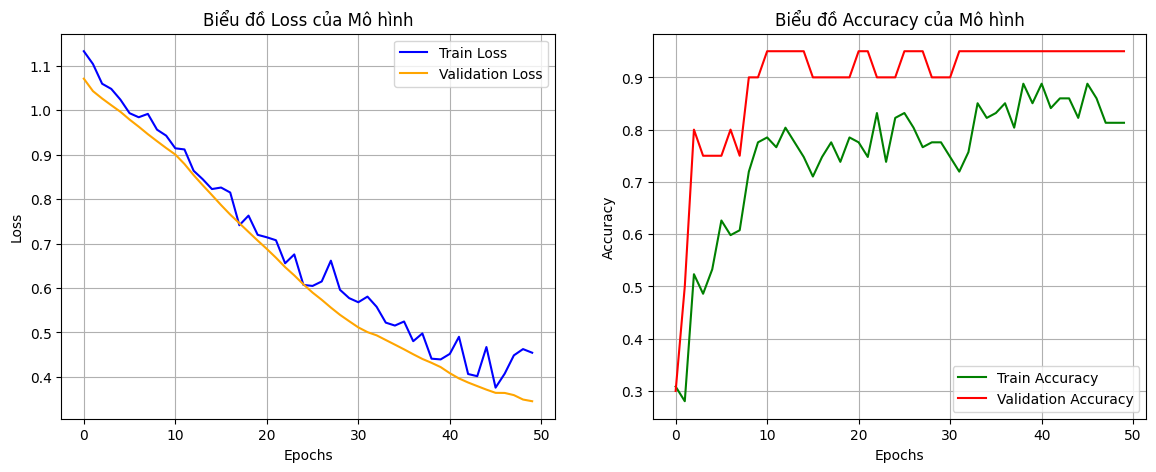

In [26]:
# Yêu cầu 4: Tiến thành training mạng nơ-ron đã xây dựng trên tập dữ liệu đã được
# xử lý ở bước 1 với 50 epochs, batch size = 64, 15% cho tập validation, dropout = 0.2
# và lưu lại các model đã huấn luyện. Chú ý: Hiển thị biểu đồ loss và Accuracy
import matplotlib.pyplot as plt

# 1. Tiến hành huấn luyện mô hình với 50 epochs, batch size 64, validation split 15%
history = model_iris.fit(
    X_train_reshaped,
    y_train_onehot,
    epochs=50,
    batch_size=64,
    validation_split=0.15,
    verbose=1
)

# 2. Lưu lại mô hình đã huấn luyện thành file đuôi .keras (chuẩn mới thay thế cho .h5)
model_iris.save('model_iris_50_epochs.keras')
print("Đã lưu mô hình thành công!")

# 3. Vẽ biểu đồ hiển thị kết quả Loss và Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ hiển thị giá trị Loss qua các epoch
ax1.plot(history.history['loss'], label='Train Loss', color='blue')
ax1.plot(history.history['val_loss'], label='Validation Loss', color='orange')
ax1.set_title('Biểu đồ Loss của Mô hình')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Biểu đồ hiển thị giá trị Accuracy qua các epoch
ax2.plot(history.history['accuracy'], label='Train Accuracy', color='green')
ax2.plot(history.history['val_accuracy'], label='Validation Accuracy', color='red')
ax2.set_title('Biểu đồ Accuracy của Mô hình')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.show()

In [27]:
#Yêu cầu 5: Đánh giá model đã được huấn luyện trên tập testing.
loss, accuracy = model_iris.evaluate(X_test_reshaped, y_test_onehot, verbose=0)

print(f"Độ chính xác trên tập testing: {accuracy:.4f}")
print(f"Loss trên tập testing: {loss:.4f}")

Độ chính xác trên tập testing (50 epochs): 0.9565
Loss trên tập testing (50 epochs): 0.3377


In [28]:
#Yêu cầu 6: Tiến hành testing với một đầu vào cụ thể.
import numpy as np

# 1. Tạo một mẫu dữ liệu đầu vào cụ thể (Ví dụ: thông số của một bông hoa ngẫu nhiên)
sample_input = np.array([[5.1, 3.5, 1.4, 0.2]])

# 2. Reshape dữ liệu đầu vào sang dạng 3D (1 sample, 4 features, 1 channel) để phù hợp với Conv1D
sample_input_reshaped = sample_input.reshape(sample_input.shape[0], sample_input.shape[1], 1)

# 3. Tiến hành dự đoán xác suất bằng mô hình model_iris
prediction_prob = model_iris.predict(sample_input_reshaped, verbose=0)

# 4. Lấy chỉ số (index) của lớp có xác suất cao nhất
predicted_class_idx = np.argmax(prediction_prob, axis=1)[0]

# 5. Giải mã chỉ số lớp thành tên loại hoa thực tế (sử dụng biến 'encoder' đã fit ở Yêu cầu 1)
predicted_flower = encoder.inverse_transform([predicted_class_idx])[0]

# In kết quả kiểm thử trực quan
print("--- KẾT QUẢ KIỂM THỬ MẪU DỮ LIỆU ĐẦU VÀO ---")
print(f"Thông số nhập vào: {sample_input[0]}")
print(f"Xác suất dự đoán cho từng lớp: {prediction_prob[0]}")
print(f"=> Loại hoa được mô hình dự đoán là: {predicted_flower}")

--- KẾT QUẢ KIỂM THỬ MẪU DỮ LIỆU ĐẦU VÀO ---
Thông số nhập vào: [5.1 3.5 1.4 0.2]
Xác suất dự đoán cho từng lớp: [0.9808975  0.01772108 0.00138147]
=> Loại hoa được mô hình dự đoán là: Iris-setosa
